# Fixed-prompt Stable Diffusion baseline

This notebook generates 12 images from validation captions using pretrained Stable Diffusion 1.5, then compares them with reference photographs. The baseline uses 30 PNDM steps, guidance scale 7.5 and seeds 7615–7626.


In [1]:
import json
from IPython.display import display
import p2_pipeline as p2
# Record package versions and GPU availability.
environment = p2.check_environment(save_requirements=True)
print(json.dumps(environment, indent=2))
assert environment["ready"], "Environment validation failed; details are recorded above."
config = p2.load_config("config.json")


{
  "utc": "2026-10-25T08:44:13.202681+00:00",
  "python": "3.10.16",
  "python_executable": "/opt/miniconda/envs/eai/bin/python",
  "platform": "Linux-5.14.0-362.13.1.el9_3.x86_64-x86_64-with-glibc2.35",
  "packages": {
    "torch": "2.5.1",
    "diffusers": "0.32.2",
    "transformers": "4.49.0",
    "accelerate": "1.5.2",
    "huggingface-hub": "0.29.3",
    "safetensors": "0.5.3",
    "numpy": "1.26.4",
    "Pillow": "11.1.0",
    "ipykernel": "6.29.5",
    "ipython": "8.34.0",
    "nbconvert": "7.16.6"
  },
  "git_commit": "453f6f78b079ab536a95375c2d4f8b5027f41d46",
  "source_sha256": "fc927d13d1006effe88166bed6bd821f66b662cc3c3e15150590182e8e0fff0b",
  "torch_cuda": "12.1",
  "cudnn": 90100,
  "cuda_available": true,
  "gpu": "Tesla V100-SXM2-32GB",
  "gpu_total_gib": 31.7393798828125,
  "missing_packages": [],
  "import_errors": {},
  "ready": true,
  "requirements_saved": true
}


In [2]:
print("Device:", p2.device_for(config))
assert (p2.local_path(config, "run_dir") / "embedding_summary.json").exists(), "The CLIP embedding artifact is required before baseline evaluation."
print("Baseline parameters:", {k: config[k] for k in ["sd_model", "steps", "guidance_scale", "image_size", "prompt_count"]})


Device: cuda
Baseline parameters: {'sd_model': 'stable-diffusion-v1-5/stable-diffusion-v1-5', 'steps': 30, 'guidance_scale': 7.5, 'image_size': 512, 'prompt_count': 12}


## Select fixed prompts

The selection first adds new COCO category coverage, then fills deterministically from validation pairs. Original cleaned captions are used as prompts. All 12 prompts and seeds are fixed before generation.


In [3]:
prompts = p2.select_prompts(config)
# Selection is fixed before model outputs are available.
assert len(prompts) == 12
for row in prompts:
    print(f"{row['index']:02d} | image {row['image_id']} | seed {row['seed']} | {row['prompt']}")


01 | image 338560 | seed 7615 | A blue fire hydrant posed on a street corner in a city.
02 | image 80932 | seed 7616 | A child taking a bite of a pizza slice on a plate.
03 | image 340894 | seed 7617 | Two computers are sitting on top of the desk.
04 | image 519522 | seed 7618 | a large tower that has a big clock at top
05 | image 259571 | seed 7619 | An orange truck driving down a street full of men in the back.
06 | image 83113 | seed 7620 | Animals trying to either move or go around fallen tree branches
07 | image 82715 | seed 7621 | A person that is surfing in the water.
08 | image 245448 | seed 7622 | A man standing with his motorcycle outside of a repair shop.
09 | image 285894 | seed 7623 | A giraffe has come to a fence line to greet visitors.
10 | image 286507 | seed 7624 | A long red train traveling through snow covered country side.
11 | image 430961 | seed 7625 | A baseball player preparing to throw a pitch during a game.
12 | image 139872 | seed 7626 | A dog laying on grass

## Generate images

Generation uses attention slicing and one sample at a time. Model revision, scheduler settings, seeds, image hashes, inference time, peak allocated CUDA memory and safety-checker results are recorded.


In [4]:
generation_summary = p2.generate(config)
display(generation_summary)
assert generation_summary["sample_count"] == 12
print("Verified:", p2.verify_generation(config)["status"])


2026-10-25 04:44:17.494099: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792917857.514222 3004259 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792917857.520294 3004259 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792917857.536464 3004259 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792917857.536481 3004259 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792917857.536483 3004259 computation_placer.cc:177] computation placer alr

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

Generated 1/12 in 10.0s


  0%|          | 0/30 [00:00<?, ?it/s]

...

Generated 11/12 in 2.1s


  0%|          | 0/30 [00:00<?, ?it/s]

Generated 12/12 in 2.1s


{'status': 'complete',
 'sample_count': 12,
 'device': 'cuda',
 'gpu': 'Tesla V100-SXM2-32GB',
 'total_inference_seconds': 33.439317390322685,
 'flagged_count': 0,
 'scheduler_class': 'PNDMScheduler',
 'model_revision': '451f4fe16113bff5a5d2269ed5ad43b0592e9a14',
 'runtime': {'utc': '2026-10-25T08:45:13.055286+00:00',
  'python': '3.10.16',
  'python_executable': '/opt/miniconda/envs/eai/bin/python',
  'platform': 'Linux-5.14.0-362.13.1.el9_3.x86_64-x86_64-with-glibc2.35',
  'packages': {'torch': '2.5.1',
   'diffusers': '0.32.2',
   'transformers': '4.49.0',
   'accelerate': '1.5.2',
   'huggingface-hub': '0.29.3',
   'safetensors': '0.5.3',
   'numpy': '1.26.4',
   'Pillow': '11.1.0',
   'ipykernel': '6.29.5',
   'ipython': '8.34.0',
   'nbconvert': '7.16.6'},
  'git_commit': '453f6f78b079ab536a95375c2d4f8b5027f41d46',
  'source_sha256': 'fc927d13d1006effe88166bed6bd821f66b662cc3c3e15150590182e8e0fff0b',
  'torch_cuda': '12.1',
  'cudnn': 90100,
  'cuda_available': True,
  'gpu': 'Te

Verified: complete


## Compare generated and reference images

All 12 comparisons are displayed below, with the reference photograph on the left and generated image on the right. Each pair is labeled with its caption, COCO image ID and seed.


01 | COCO 338560 | seed 7615
A blue fire hydrant posed on a street corner in a city.


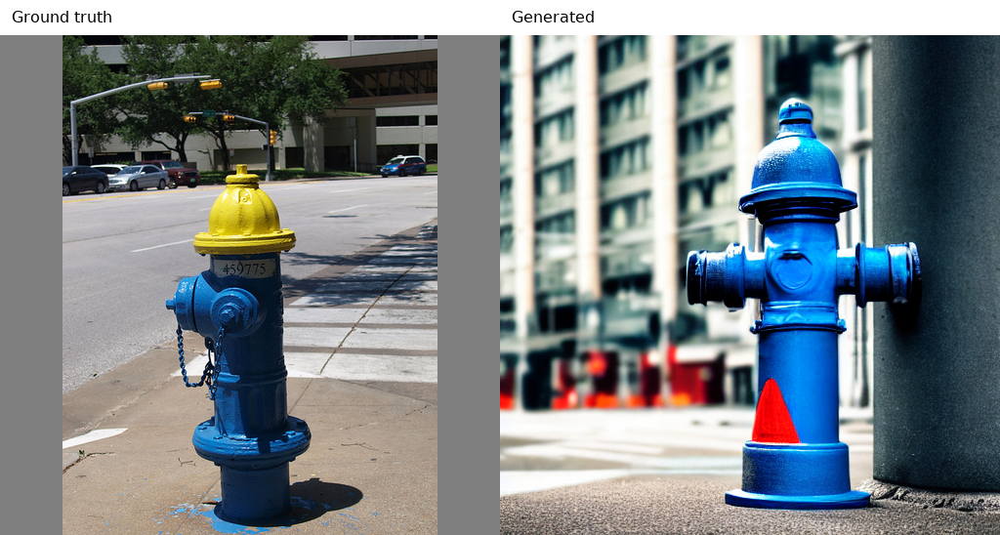

02 | COCO 80932 | seed 7616
A child taking a bite of a pizza slice on a plate.


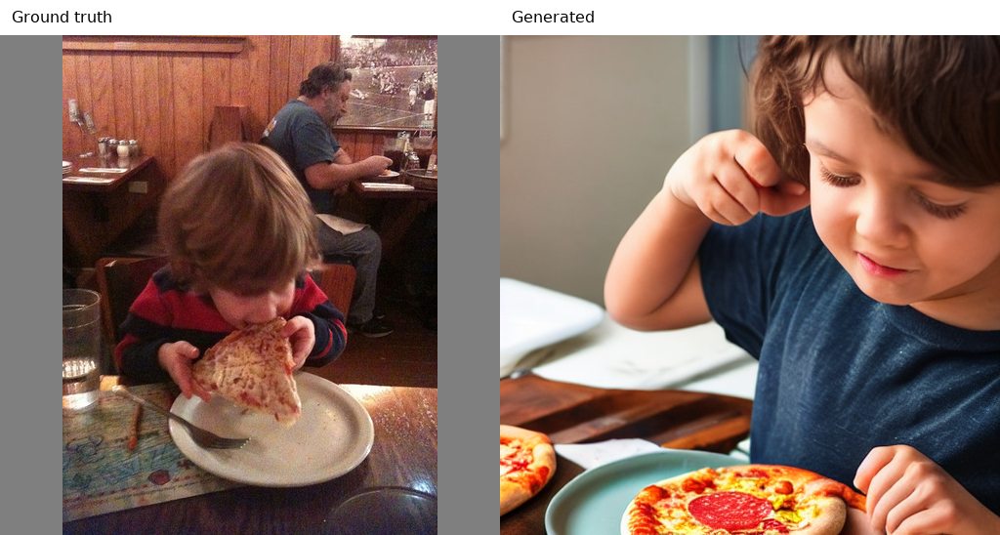

03 | COCO 340894 | seed 7617
Two computers are sitting on top of the desk.


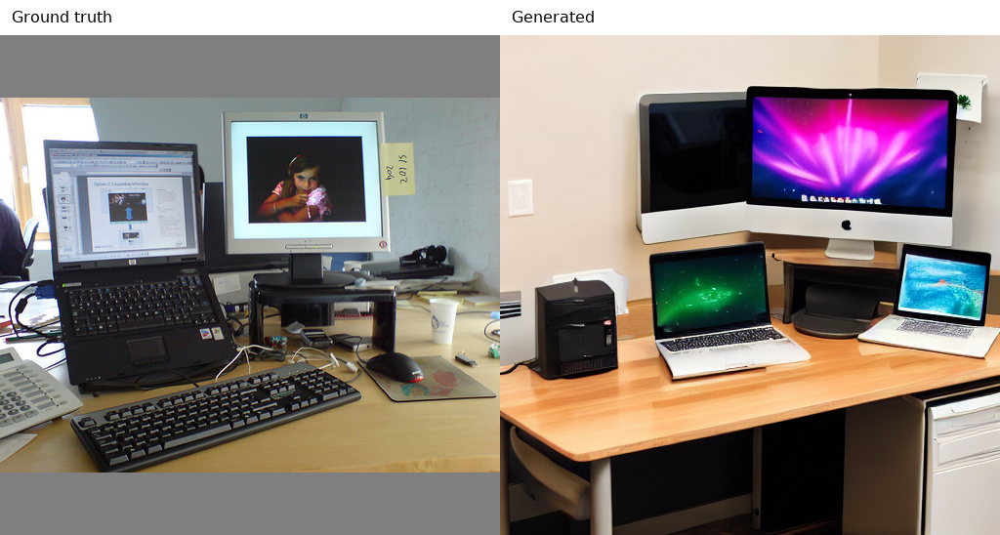

04 | COCO 519522 | seed 7618
a large tower that has a big clock at top


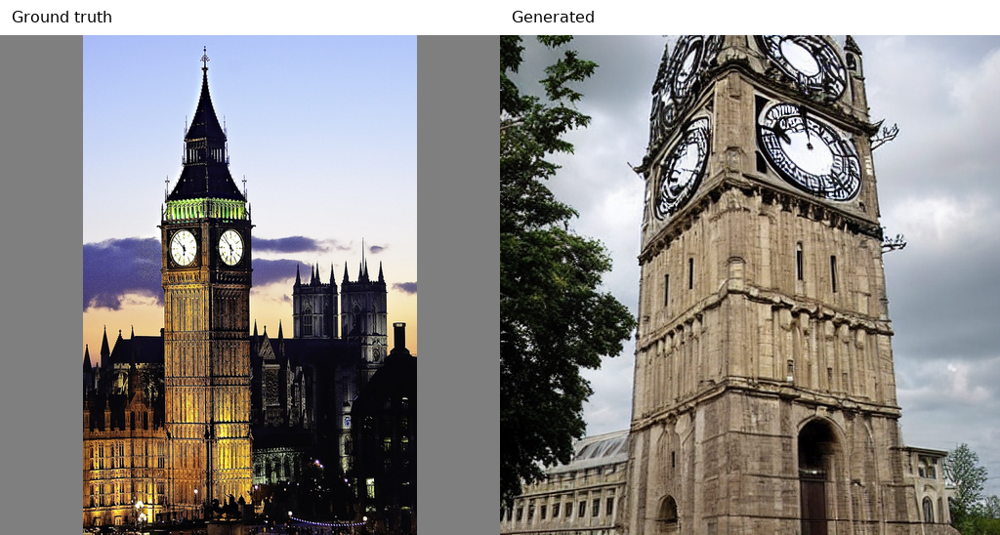

05 | COCO 259571 | seed 7619
An orange truck driving down a street full of men in the back.


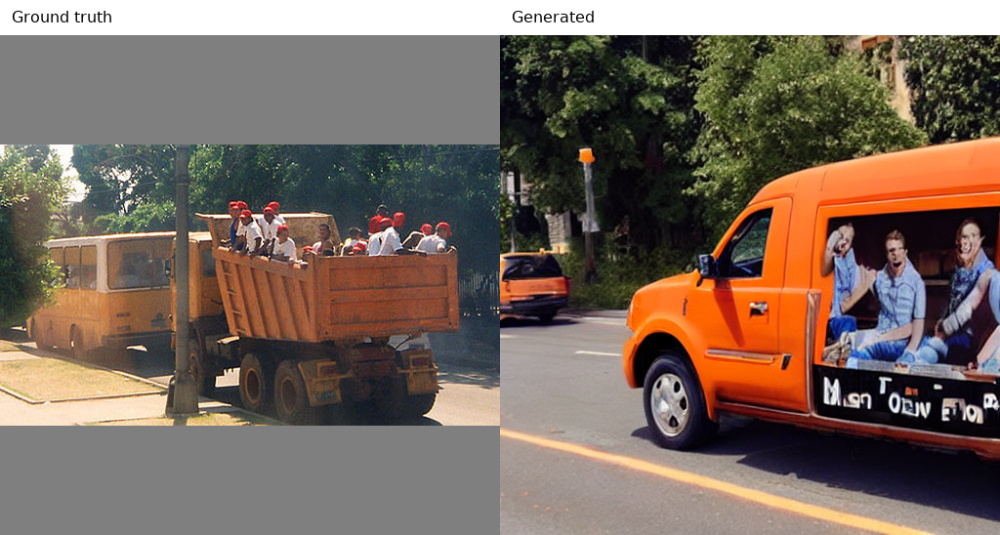

06 | COCO 83113 | seed 7620
Animals trying to either move or go around fallen tree branches


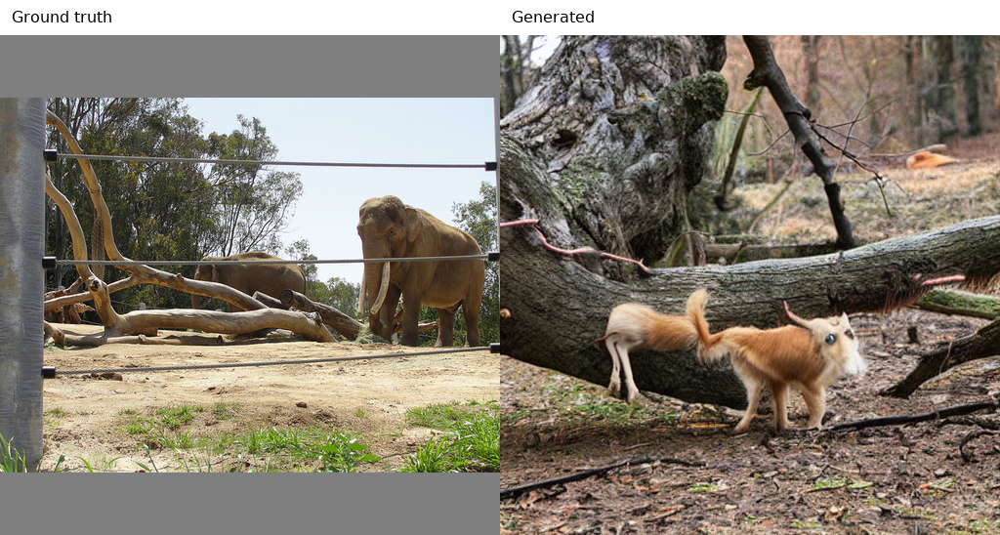

07 | COCO 82715 | seed 7621
A person that is surfing in the water.


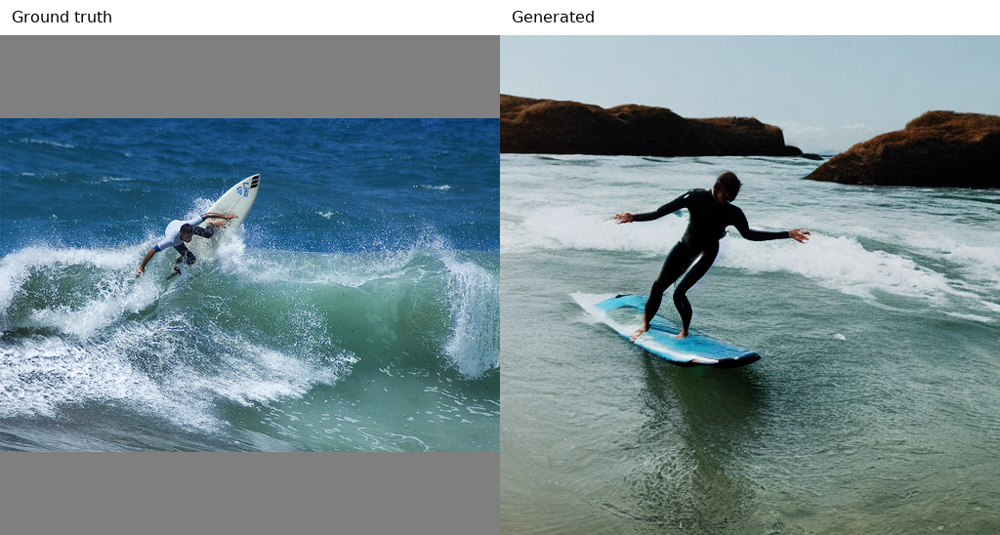

08 | COCO 245448 | seed 7622
A man standing with his motorcycle outside of a repair shop.


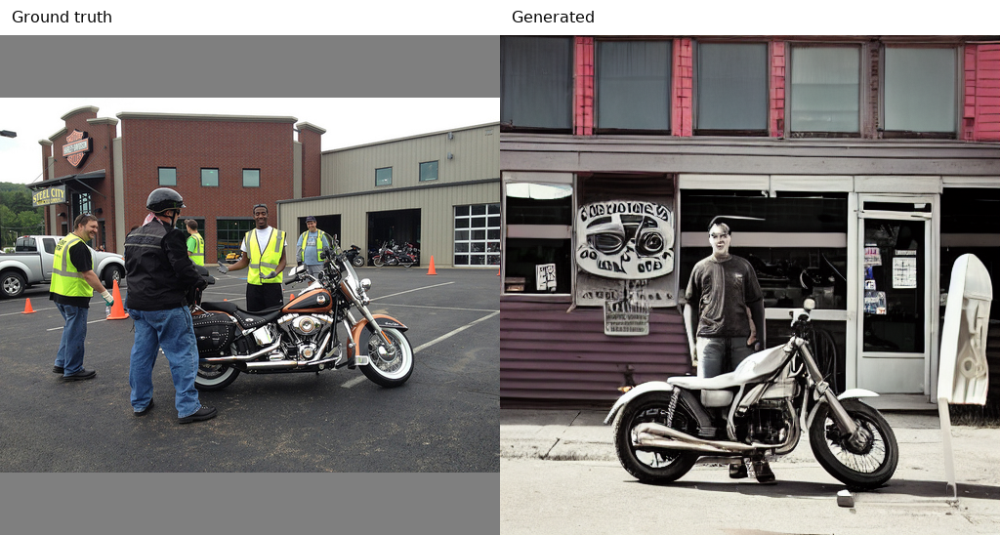

09 | COCO 285894 | seed 7623
A giraffe has come to a fence line to greet visitors.


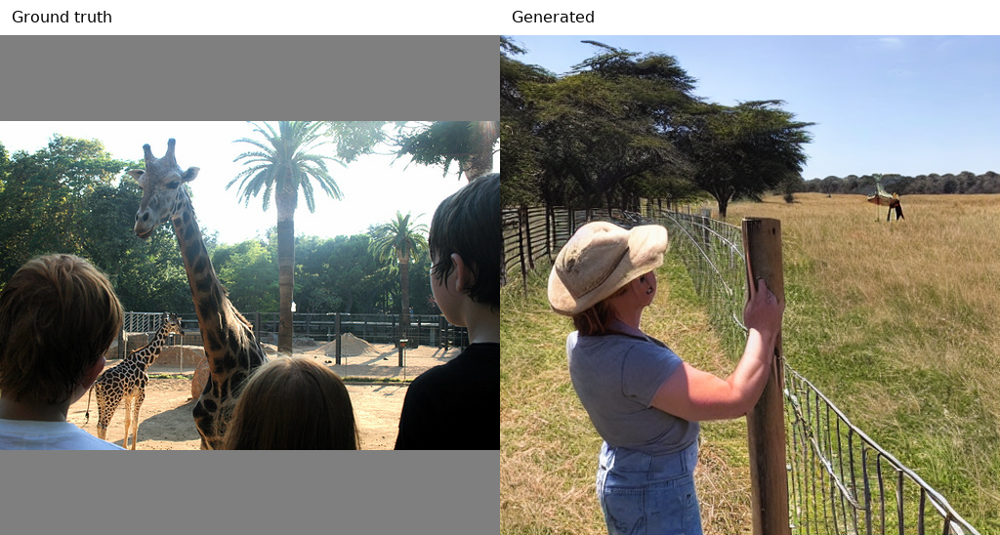

10 | COCO 286507 | seed 7624
A long red train traveling through snow covered country side.


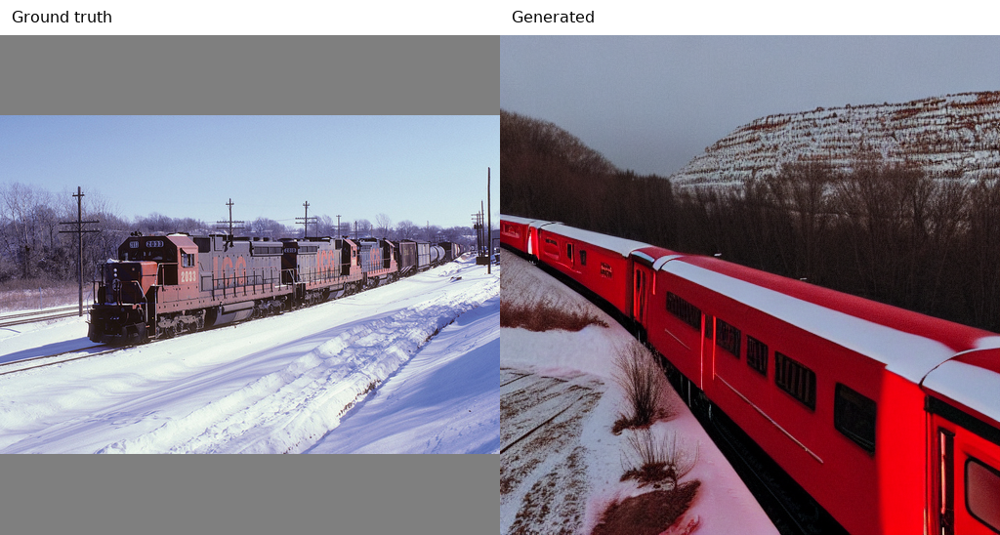

11 | COCO 430961 | seed 7625
A baseball player preparing to throw a pitch during a game.


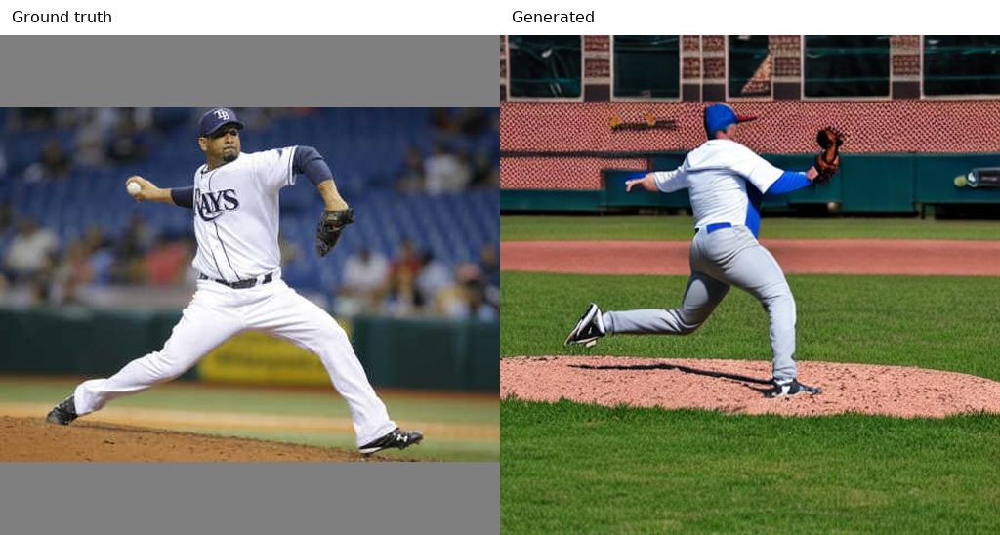

12 | COCO 139872 | seed 7626
A dog laying on grass near a flying disc.


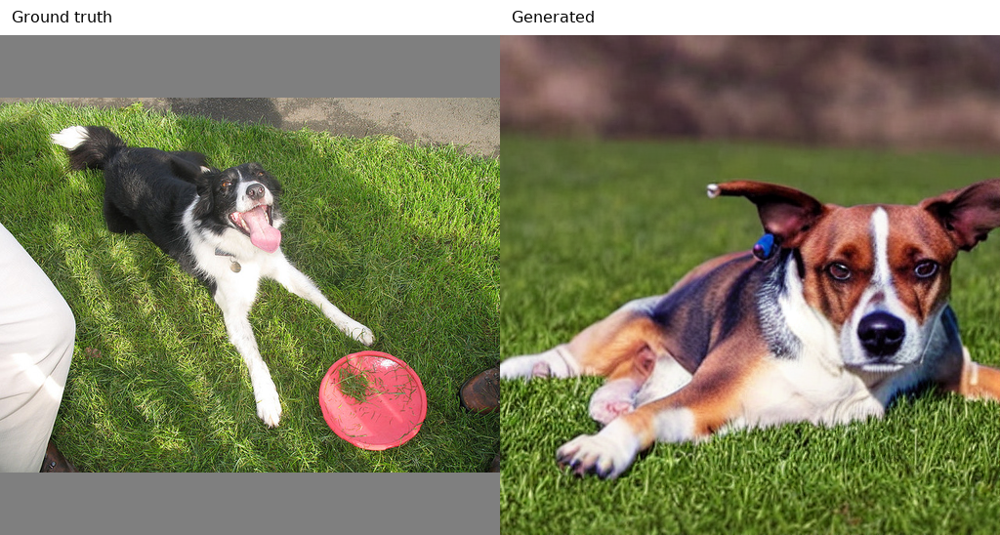

In [5]:
p2.gallery(config)
run = p2.local_path(config, "run_dir")
for row in prompts:
    print(f"{row['index']:02d} | COCO {row['image_id']} | seed {row['seed']}")
    print(row["prompt"])
    with p2.Image.open(run / "comparisons" / f"{row['index']:02d}_{row['image_id']}.png") as image:
        display(image)


## Qualitative analysis

Broad objects and scenes generally follow the captions, while some samples show limitations in counts, relations and object presence. Example 03 shows a possible mismatch with the requested number of computers. In Example 05, people appear as graphics on the vehicle rather than passengers in the back. Example 12 does not clearly show the requested flying disc. Differences from reference photographs are acceptable when those details are not specified by the caption.

The model performs conditional sampling: a latent representation is denoised under text conditioning and decoded into an image. A discriminative model predicts a label from an input; this model samples an image from text.

[Reference image sources and licenses](data/source_attributions.json).
